## 자동차 연비 예측


In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

SEED = 42


### 데이터 준비


In [47]:
mpg = sns.load_dataset("mpg")
numeric_columns = ["weight", "horsepower"]
category_columns = ["origin"]
X = mpg[numeric_columns + ["model_year"] + category_columns].copy()
y = mpg["mpg"].copy()

display(mpg.head())
display(X.isna().sum().rename("missing_count"))


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


weight        0
horsepower    6
model_year    0
origin        0
Name: missing_count, dtype: int64

### 학습·검증·테스트 분리


In [48]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=SEED,
)

print(f"학습 {len(X_train)}건 / 검증 {len(X_val)}건 / 테스트 {len(X_test)}건")


학습 238건 / 검증 80건 / 테스트 80건


### 전처리와 다중 선형 회귀


In [49]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), category_columns),
])
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

basic_model = LinearRegression()
basic_model.fit(X_train_processed, y_train)
basic_prediction = basic_model.predict(X_val_processed)


### 기본 모델 평가


In [50]:
def regression_metrics(actual, predicted):
    return {
        "MAE_mpg": mean_absolute_error(actual, predicted),
        "RMSE_mpg": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }


display(pd.DataFrame({
    "train": regression_metrics(y_train, basic_model.predict(X_train_processed)),
    "validation": regression_metrics(y_val, basic_prediction),
}).T)


,MAE_mpg,RMSE_mpg,R2
train,3.138365,4.098270,0.712010
validation,3.488138,4.792092,0.690873


## 추가 실험

### 기본 입력에서 제조 지역 제외·모델 연도 추가

무게·마력은 유지하고, 제조 지역 포함 여부와 모델 연도 추가 여부를 바꾼다. `model_year`는 두 자리로 기록된 자동차의 모델 연도다.


In [51]:
models = {"linear_basic": basic_model}
preprocessors = {"linear_basic": preprocessor}
train_inputs = {"linear_basic": X_train_processed}
val_inputs = {"linear_basic": X_val_processed}

input_combinations = {
    "linear_without_origin": (["weight", "horsepower"], []),
    "linear_with_year": (["weight", "horsepower", "model_year"], ["origin"]),
    "linear_without_origin_with_year": (["weight", "horsepower", "model_year"], []),
}
for name, (numeric_inputs, category_inputs) in input_combinations.items():
    transformer = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_inputs),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), category_inputs),
    ])
    train_inputs[name] = transformer.fit_transform(X_train)
    val_inputs[name] = transformer.transform(X_val)
    preprocessors[name] = transformer
    models[name] = LinearRegression()


### 기본 입력·연도 추가 입력의 다중 다항 회귀

숫자 입력에 2차 다항식을 적용해 원래 항·제곱항·두 변수의 곱을 사용한다. 제조 지역은 원핫 인코딩하고, 숫자 항은 생성 후 표준화한다.


In [52]:
polynomial_combinations = {
    "polynomial_basic": ["weight", "horsepower"],
    "polynomial_with_year": ["weight", "horsepower", "model_year"],
}
for name, columns in polynomial_combinations.items():
    transformer = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
            ("scaler", StandardScaler()),
        ]), columns),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), category_columns),
    ])
    train_inputs[name] = transformer.fit_transform(X_train)
    val_inputs[name] = transformer.transform(X_val)
    preprocessors[name] = transformer
    models[name] = LinearRegression()

display(pd.DataFrame(
    train_inputs["polynomial_with_year"],
    columns=preprocessors["polynomial_with_year"].get_feature_names_out(),
    index=X_train.index,
).head())


,numeric__weight,numeric__horsepower,numeric__model_year,numeric__weight^2,numeric__weight horsepower,numeric__weight model_year,numeric__horsepower^2,numeric__horsepower model_year,numeric__model_year^2,category__origin_europe,category__origin_japan,category__origin_usa
346,-1.101993,-0.971313,1.405465,-1.002412,-0.932508,-0.969913,-0.807055,-0.895984,1.429248,0.0,1.0,0.0
355,-0.930071,-0.758030,1.405465,-0.887635,-0.803597,-0.778794,-0.686679,-0.652421,1.429248,0.0,1.0,0.0
203,-1.386553,-0.864671,-0.005930,-1.175279,-0.973823,-1.434735,-0.748562,-0.907636,-0.029251,1.0,0.0,0.0
246,-1.196847,-1.371219,0.558628,-1.062404,-1.097839,-1.172261,-0.996202,-1.411300,0.543001,0.0,1.0,0.0
332,-1.362840,-1.104615,1.123186,-1.161688,-1.045278,-1.289910,-0.875402,-1.071514,1.130116,1.0,0.0,0.0


### 같은 다항 입력으로 Ridge·Lasso 비교

무게·마력·모델 연도의 2차 다항 특성과 제조 지역을 사용한다. 계수 크기에 벌점을 주는 Ridge와 Lasso를 적용하며, 규제 강도는 Ridge `0.1·1·10`, Lasso `0.01·0.1·1`로 비교한다.


In [53]:
regularization_models = {}
for alpha in [0.1, 1.0, 10.0]:
    regularization_models[f"polynomial_ridge_{alpha:g}"] = Ridge(alpha=alpha)
for alpha in [0.01, 0.1, 1.0]:
    regularization_models[f"polynomial_lasso_{alpha:g}"] = Lasso(alpha=alpha, max_iter=100_000)

models.update(regularization_models)
for name in regularization_models:
    train_inputs[name] = train_inputs["polynomial_with_year"]
    val_inputs[name] = val_inputs["polynomial_with_year"]
    preprocessors[name] = preprocessors["polynomial_with_year"]


### 무게·마력·모델 연도의 2차 다항 회귀와 Ridge

제조 지역을 제외하고 숫자 변수 3개만 사용한다. 원래 항 3개·제곱항 3개·교차항 3개를 표준화하고, Ridge `alpha=0.1`을 적용한다.


In [54]:
without_origin_name = "polynomial_ridge_0.1_without_origin"
without_origin_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
    ]), ["weight", "horsepower", "model_year"]),
])
train_inputs[without_origin_name] = without_origin_preprocessor.fit_transform(X_train)
val_inputs[without_origin_name] = without_origin_preprocessor.transform(X_val)
preprocessors[without_origin_name] = without_origin_preprocessor
models[without_origin_name] = Ridge(alpha=0.1)


### 학습·검증 결과 비교와 최종 모델

같은 분할에서 학습·검증 오차를 비교한다. 제조 지역을 제외하면 검증 RMSE는 약 0.057 mpg 증가하고 특성은 12개에서 9개로 줄어든다. 이 차이와 입력 구성의 간결성을 고려해 무게·마력·모델 연도의 2차 다항 특성에 Ridge `alpha=0.1`을 적용한 모델을 최종 모델로 사용한다.


In [55]:
comparison_rows = []
for name, model in models.items():
    model.fit(train_inputs[name], y_train)
    train_metrics = regression_metrics(y_train, model.predict(train_inputs[name]))
    val_metrics = regression_metrics(y_val, model.predict(val_inputs[name]))
    comparison_rows.append({
        "model": name,
        "train_MAE_mpg": train_metrics["MAE_mpg"],
        "train_RMSE_mpg": train_metrics["RMSE_mpg"],
        "train_R2": train_metrics["R2"],
        "val_MAE_mpg": val_metrics["MAE_mpg"],
        "val_RMSE_mpg": val_metrics["RMSE_mpg"],
        "val_R2": val_metrics["R2"],
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison)
validation_best_name = comparison.loc[comparison["val_RMSE_mpg"].idxmin(), "model"]
print("검증 RMSE 최소 모델:", validation_best_name)
selected_name = without_origin_name
selected_model = models[selected_name]
print("최종 모델:", selected_name)

origin_comparison = comparison.loc[
    comparison["model"].isin(["polynomial_ridge_0.1", without_origin_name])
]
display(origin_comparison)


,model,train_MAE_mpg,train_RMSE_mpg,train_R2,val_MAE_mpg,val_RMSE_mpg,val_R2
0,linear_basic,3.138365,4.098270,0.712010,3.488138,4.792092,0.690873
1,linear_without_origin,3.174695,4.142321,0.705785,3.627474,4.972034,0.667222
2,linear_with_year,2.502144,3.236554,0.820385,2.933664,3.912208,0.793970
3,linear_without_origin_with_year,2.572765,3.329101,0.809966,3.045470,4.030533,0.781319
4,polynomial_basic,2.821852,3.809009,0.751229,3.263306,4.652473,0.708624
5,polynomial_with_year,1.897302,2.552421,0.888293,2.516859,3.561608,0.829243
6,polynomial_ridge_0.1,1.961577,2.609265,0.883262,2.512457,3.494135,0.835652
7,polynomial_ridge_1,2.049063,2.696632,0.875313,2.550256,3.518172,0.833383
8,polynomial_ridge_10,2.238008,2.931832,0.852614,2.729717,3.700355,0.815680
9,polynomial_lasso_0.01,2.012700,2.673048,0.877485,2.530079,3.500572,0.835045


검증 RMSE 최소 모델: polynomial_ridge_0.1
최종 모델: polynomial_ridge_0.1_without_origin


,model,train_MAE_mpg,train_RMSE_mpg,train_R2,val_MAE_mpg,val_RMSE_mpg,val_R2
6,polynomial_ridge_0.1,1.961577,2.609265,0.883262,2.512457,3.494135,0.835652
12,polynomial_ridge_0.1_without_origin,1.984815,2.667493,0.877993,2.515578,3.550923,0.830266


### 규제에 따른 계수와 최종 모델의 계수

같은 입력에서 규제에 따른 계수와 0인 계수 수를 비교한다. 최종 모델의 숫자 항 계수는 표준화된 각 항에 곱하는 값이다.


In [56]:
coefficient_models = {"polynomial_with_year": models["polynomial_with_year"]}
coefficient_models.update(regularization_models)
coefficients = {name: model.coef_.copy() for name, model in coefficient_models.items()}
coefficient_table = pd.DataFrame.from_dict(
    coefficients,
    orient="index",
    columns=preprocessors["polynomial_with_year"].get_feature_names_out(),
)
display(coefficient_table)
display(pd.DataFrame([
    {"model": name, "zero_coefficients": int(np.count_nonzero(model.coef_ == 0))}
    for name, model in coefficient_models.items()
]))

without_origin_model = models[without_origin_name]
display(pd.DataFrame({
    "feature": without_origin_preprocessor.get_feature_names_out(),
    "coefficient": without_origin_model.coef_,
}))
print("제조 지역 제외 모델의 절편:", without_origin_model.intercept_)


,numeric__weight,numeric__horsepower,numeric__model_year,numeric__weight^2,numeric__weight horsepower,numeric__weight model_year,numeric__horsepower^2,numeric__horsepower model_year,numeric__model_year^2,category__origin_europe,category__origin_japan,category__origin_usa
polynomial_with_year,-24.628165,24.979858,-25.832644,6.528670,7.390536,10.880942,-2.381964,-27.321905,30.449367,0.906208,-0.120760,-0.785448
polynomial_ridge_0.1,-5.243908,6.822885,-8.395803,5.731069,4.357134,-5.902343,0.886253,-11.342139,13.647022,0.889584,-0.093646,-0.795937
polynomial_ridge_1,-3.133817,-0.585903,0.394114,3.656983,3.950441,-5.871589,2.383219,-5.287519,4.063341,0.817389,0.025056,-0.842446
polynomial_ridge_10,-2.292245,-1.381198,1.516157,0.598756,1.477679,-2.918756,1.827617,-2.238644,1.967420,0.774268,0.286564,-1.060832
polynomial_lasso_0.01,-0.000000,0.000000,-0.000000,4.234174,4.350039,-9.626182,1.813910,-5.623946,5.104677,0.869253,0.000000,-0.726647
polynomial_lasso_0.1,-0.000000,-0.000000,0.000000,0.000000,0.143368,-4.203455,1.657954,-2.545164,3.667984,0.088121,-0.000000,-1.298279
polynomial_lasso_1,-4.428522,-0.440841,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,1.952952,0.000000,0.000000,-0.000000


,model,zero_coefficients
0,polynomial_with_year,0
1,polynomial_ridge_0.1,0
2,polynomial_ridge_1,0
3,polynomial_ridge_10,0
4,polynomial_lasso_0.01,4
5,polynomial_lasso_0.1,5
6,polynomial_lasso_1,9


,feature,coefficient
0,numeric__weight,-6.935423
1,numeric__horsepower,6.177566
2,numeric__model_year,-7.980139
3,numeric__weight^2,6.535758
4,numeric__weight horsepower,3.993134
5,numeric__weight model_year,-5.107360
6,numeric__horsepower^2,1.356709
7,numeric__horsepower model_year,-11.076071
8,numeric__model_year^2,13.002507


제조 지역 제외 모델의 절편: 23.260924369747887


### 최종 모델의 검증 실제값과 예측값 비교


,weight,horsepower,model_year,origin,actual_mpg,predicted_mpg,residual_mpg,absolute_error_mpg
150,2391,93.0,74,japan,26.0,24.010705,1.989295,1.989295
319,2542,75.0,80,japan,31.3,29.957309,1.342691,1.342691
7,4312,215.0,70,usa,14.0,13.243632,0.756368,0.756368
1,3693,165.0,70,usa,15.0,13.572725,1.427275,1.427275
90,4952,198.0,73,usa,12.0,13.479642,-1.479642,1.479642


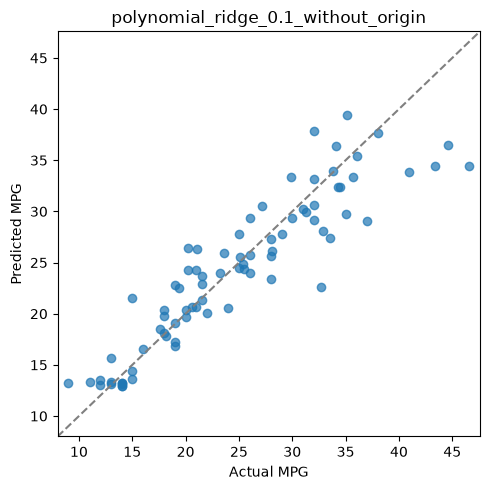

In [57]:
validation_prediction = selected_model.predict(val_inputs[selected_name])
validation_errors = X_val.copy()
validation_errors["actual_mpg"] = y_val
validation_errors["predicted_mpg"] = validation_prediction
validation_errors["residual_mpg"] = y_val - validation_prediction
validation_errors["absolute_error_mpg"] = np.abs(y_val - validation_prediction)
display(validation_errors.head())

values = np.concatenate([y_val.to_numpy(), validation_prediction])
limits = [values.min() - 1, values.max() + 1]
plt.figure(figsize=(5, 5))
plt.scatter(y_val, validation_prediction, alpha=0.7)
plt.plot(limits, limits, "--", color="gray")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title(selected_name)
plt.tight_layout()
plt.show()


### 최종 테스트

선택한 모델과 학습 데이터에서 구한 전처리 기준으로 테스트 데이터를 평가한다.


In [58]:
test_input = preprocessors[selected_name].transform(X_test)
test_prediction = selected_model.predict(test_input)
display(pd.DataFrame({
    "train": regression_metrics(y_train, selected_model.predict(train_inputs[selected_name])),
    "test": regression_metrics(y_test, test_prediction),
}).T)


,MAE_mpg,RMSE_mpg,R2
train,1.984815,2.667493,0.877993
test,1.830397,2.359992,0.896412
